# Selecting the number of CFMs

This tutorial demonstrates how to determine the optimal number of CFMs (`num_CFMs`) for modeling data using `topic3d`.

**What you will learn:**
- Why the number of CFMs is a critical hyperparameter
- How to find the number of CFMs using a combination of two criteria
- How to verify that this is correct

## Conceptual overview

In topic modelling, the number of topics controls the resolution at which structural patterns are detected:

- Too few topics → underfitting (distinct conformations are merged)
- Too many topics → overfitting (noise is captured as structure)

In `topic3d`, topics correspond to **chromatin folding motifs (CFMs)**.
Choosing the right number of CFMs is therefore essential for biological interpretability.

## Strategy

The typical approach is to:

1. Train models with different numbers of CFMs
2. Evaluate each model using the quantitative metrics NPMI coherence and mean proportion of empty CFMs
3. Identify a stable or optimal region

This notebook implements this workflow.

## Running the hyperparameter search

The following cells run training across a range of topic numbers and collect evaluation metrics.

In [1]:
from os import path
from glob import glob
import joblib as jl
import numpy as np
import matplotlib.pyplot as plt
from topic3d.datatypes import PWProxArrayStack
from topic3d.results import Topic3DModelPool
from IPython.display import Image

Loading the training data is essential since the NPMI coherence needs it.

In [2]:
data = PWProxArrayStack(np.load("./data/sample_exp.npy"))
data.shape

(1745, 946)

We need to collect all the models that were trained with different numbers of CFMs.

In [3]:
model_fps = sorted(glob("./models/bintu_models/*"))
len(model_fps)

20

After getting the model file paths, we use `topic3d.results.Topic3DModelPool`, a special class for handling collections of LDA models. It has various functions to compute different average metrics on multiple models.

In [4]:
model_pool = Topic3DModelPool(model_file_paths=model_fps)
print("Number of models: ", len(model_pool.models))
print("Number of CFMs by model: ", *model_pool.num_CFMs_by_model)

Number of models:  20
Number of CFMs by model:  10 10 10 10 10 20 20 20 20 20 30 30 30 30 30 40 40 40 40 40


/home/ganesh/miniconda3/envs/chromtopic-dev/lib/python3.13/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LatentDirichletAllocation from version 1.2.2 when using version 1.7.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


The best model of the collection can be picked by a simple function that takes the basis of ranking. The coherence is the best method for this, but the perplexity can also be used.

To find the best number of CFMs, this simple function takes into account the coherence and the mean proportion of empty CFMs as a function of their number, and automatically outputs the optimum value. The function further below can then be used to pick the best model out of these.

In [10]:
model_pool.find_best_num_CFMs(data_used=data)

np.int64(30)

In [6]:
model_pool.find_best_model(by="coherence", data_used=data)

,n_components,30
,doc_topic_prior,None
,topic_word_prior,None
,learning_method,'online'
,learning_decay,0.7
,learning_offset,10.0
,max_iter,3000
,batch_size,512
,evaluate_every,-1
,total_samples,1000000.0
,perp_tol,0.1


To verify that this is indeed correct (standard recommended practice), we can plot both metrics as a function of the number of CFMs. As is clear from the plots, the optimum is indeed 30 CFMs because the coherence is maximized while maintaining near-zero empty CFMs across all trainings.

<bound method Figure.show of <Figure size 614.4x460.8 with 1 Axes>>

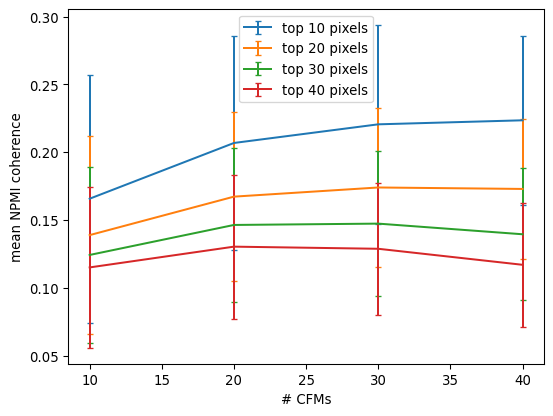

In [22]:
fig = model_pool.plot_mean_coherence_vs_num_CFMs(data=data)
fig.set_dpi(96)
fig.show

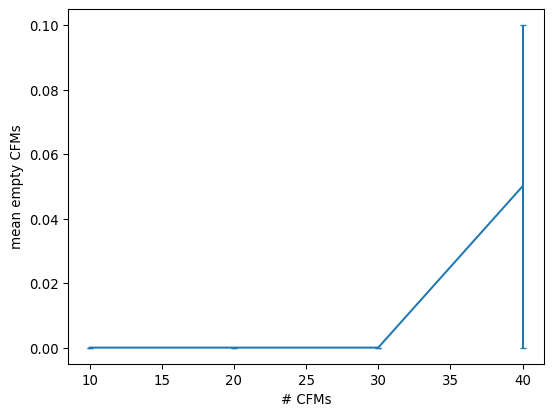

In [5]:
fig = model_pool.plot_mean_empty_vs_num_CFMs()
fig.set_dpi(96)
fig.show()

## Summary

When selecting the number of CFMs, look for:

- A plateau or maximum in coherence
- Close to zero proportion of empty CFMs

In datasets we explored, we noticed that biological interpretability was indeed there at the optimum number of CFMs, but it is unclear if this corresponds to optimal interpretability.

## Practical considerations

- Use a sufficiently large dataset to avoid noisy estimates
- Run multiple random initializations


## Potential next steps

- Train a final model using the selected number of CFMs
- Perform downstream analysis (embedding, clustering)
- Compare conditions (e.g. WT vs perturbation)
